# Physics-AI Symbiosis in ANSI C: Four Small Experiments, Many Conclusions, and Assignments

**Colin Casey, 2026.** A hands-on companion to B. Jalali, A. Kadambi and V. Roychowdhury, "Physics-AI Symbiosis," arXiv:2109.05959 (2021) [1].

The paper argues that physics and AI should be blended, not used separately, and sorts the blend into three themes. Each theme gets one small, strict **ANSI C89** program here (no libraries beyond `libm`), compiled and run from this notebook, then plotted and checked in Python.

| Paper section | Idea | Program | What it shows |
|---|---|---|---|
| Introduction | the Kalman filter: physics model + noisy data | `kalman.c` | blending beats either alone |
| 2. Nature as a Computer | a nonlinear optical element as a kernel | `nlse_kernel.c` | a Kerr fiber makes rings linearly separable |
| 2. Physics-inspired algorithms | the Phase Stretch Transform | `pst.c` | faint, nearly transparent cells become visible |
| 3. Nature blends with computer | discovering physical laws from data | `discover.c` | sparse regression recovers $y_0 + v_0t - \tfrac12 gt^2$ |
| (all) | CUDA versions of the heavy kernels | `nlse_cuda.cu`, `pst_cuda.cu` | batched cuFFT reproduces the CPU results, ~50× faster |

Then: **several alternative conclusions** (scientific machine learning beyond spectral regression) and **assignments** built from the paper. Kernel: **py312**; compiler: gcc (MSYS2), `-std=c89 -pedantic -Wall -Wextra`.

In [1]:
import subprocess, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.prop_cycle': plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"])})
HERE = pathlib.Path.cwd()
SRC, OUT = HERE / 'c', HERE / 'out'
OUT.mkdir(exist_ok=True)

def build_and_run(name):
    exe = OUT / f'{name}.exe'
    b = subprocess.run(['gcc', '-std=c89', '-pedantic', '-Wall', '-Wextra', '-O2', str(SRC / f'{name}.c'), '-o', str(exe), '-lm'],
                       capture_output=True, text=True)
    print(f'gcc -std=c89 -pedantic -Wall -Wextra {name}.c -> exit {b.returncode};', 'no warnings' if not (b.stdout + b.stderr).strip() else (b.stdout + b.stderr))
    r = subprocess.run([str(exe)], capture_output=True, text=True, cwd=OUT)
    print(r.stdout + r.stderr)

print(subprocess.run(['gcc', '--version'], capture_output=True, text=True).stdout.splitlines()[0])

gcc (Rev5, Built by MSYS2 project) 15.1.0


---
## 1. Introduction: the Kalman filter, the original physics-AI blend

**In plain words.** The paper opens with Apollo: crude computers, imperfect sensors, and neither the physics model nor the measurements alone could be trusted. The Kalman filter blends them: predict with physics, then correct with the measurement, weighting each by how uncertain it is.

**The math.** State $\mathbf x = (x, v)$, model $\mathbf x_{k+1} = F\mathbf x_k + \text{noise}$ with $F = \begin{pmatrix}1 & \Delta t\\ 0 & 1\end{pmatrix}$, measurement $z_k = x_k + \text{noise}$. Predict $\hat{\mathbf x}^- = F\hat{\mathbf x}$, $P^- = FPF^\top + Q$; gain $K = P^-H^\top(HP^-H^\top + R)^{-1}$; update $\hat{\mathbf x} = \hat{\mathbf x}^- + K(z - H\hat{\mathbf x}^-)$.

In [2]:
build_and_run('kalman')

gcc -std=c89 -pedantic -Wall -Wextra kalman.c -> exit 0; no warnings
position RMSE over 200 steps:
  sensor only  2.083 m
  physics only 7.841 m
  Kalman       0.488 m
final velocity: truth 4.470, Kalman 4.304 m/s



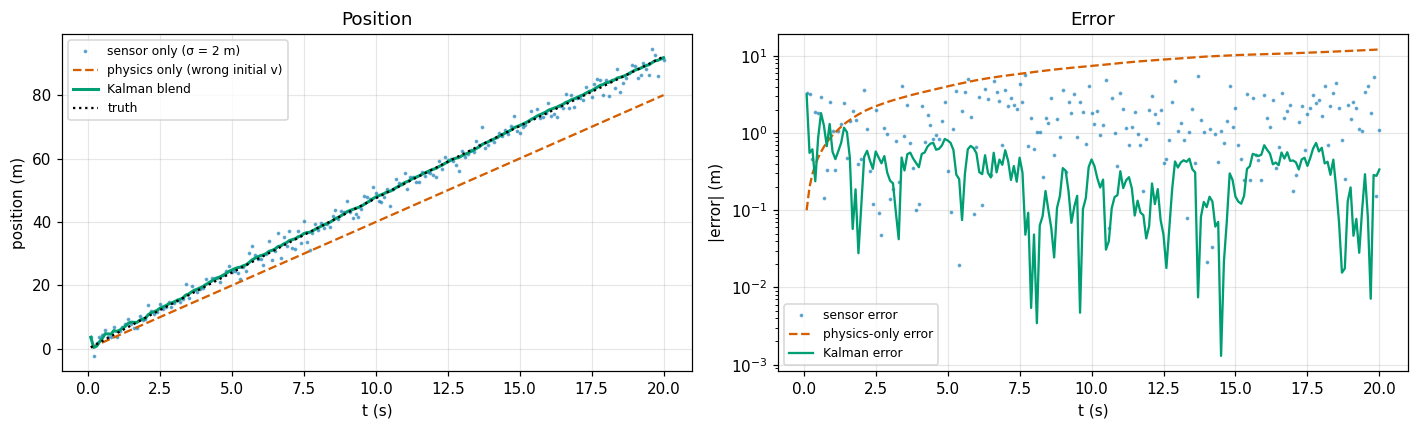

Figure: the sensor scatters by about 2 m, the physics-only estimate drifts away steadily, and the Kalman estimate follows the truth closely after a short settling time.


In [3]:
k = pd.read_csv(OUT / 'kalman.csv')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(k.t, k.measurement, '.', ms=3, alpha=0.5, label='sensor only (σ = 2 m)')
ax[0].plot(k.t, k.physics_only, '--', label='physics only (wrong initial v)')
ax[0].plot(k.t, k.kalman, '-', lw=2, label='Kalman blend')
ax[0].plot(k.t, k.truth, ':', color='k', label='truth')
ax[0].set_xlabel('t (s)'); ax[0].set_ylabel('position (m)'); ax[0].legend(fontsize=8); ax[0].set_title('Position')
ax[1].plot(k.t, np.abs(k.measurement - k.truth), '.', ms=3, alpha=0.5, label='sensor error')
ax[1].plot(k.t, np.abs(k.physics_only - k.truth), '--', label='physics-only error')
ax[1].plot(k.t, np.abs(k.kalman - k.truth), '-', label='Kalman error')
ax[1].set_yscale('log'); ax[1].set_xlabel('t (s)'); ax[1].set_ylabel('|error| (m)'); ax[1].legend(fontsize=8); ax[1].set_title('Error')
plt.tight_layout(); plt.show()
print('Figure: the sensor scatters by about 2 m, the physics-only estimate drifts away steadily, and the Kalman '
      'estimate follows the truth closely after a short settling time.')

---
## 2. Nature as a computer: a Kerr fiber as a kernel

**In plain words.** The paper describes writing data onto a laser spectrum, letting a nonlinear optical element transform it, reading the output spectrum, and training only a light linear classifier [12], [13]. The optics does the hard, nonlinear part "for free" at the speed of light.

**The experiment.** Two concentric rings of points can't be split by a straight line. Each point $(x, y)$ is written onto a pulse's spectral **phase** ($x$ as chirp, $y$ as cubic phase) and sent through a fiber, simulated by the split-step Fourier method for the nonlinear Schrödinger equation
$$\partial_z A = -\tfrac{i\beta_2}{2}\partial_t^2 A + i\gamma|A|^2A$$
The 24-bin output spectrum feeds logistic regression. With $\gamma = 0$ (dispersion only) the spectrum's *magnitude* never changes, so the data are invisible: the classifier must sit at chance. With $\gamma > 0$, self-phase modulation turns phase into spectral shape.

In [4]:
build_and_run('nlse_kernel')

gcc -std=c89 -pedantic -Wall -Wextra nlse_kernel.c -> exit 0; no warnings


test accuracy on 200 held-out points (chance = 0.5):
  linear classifier on raw (x, y)          0.450
  ... on fiber output, dispersion only     0.500
  ... on fiber output, Kerr nonlinearity   0.890



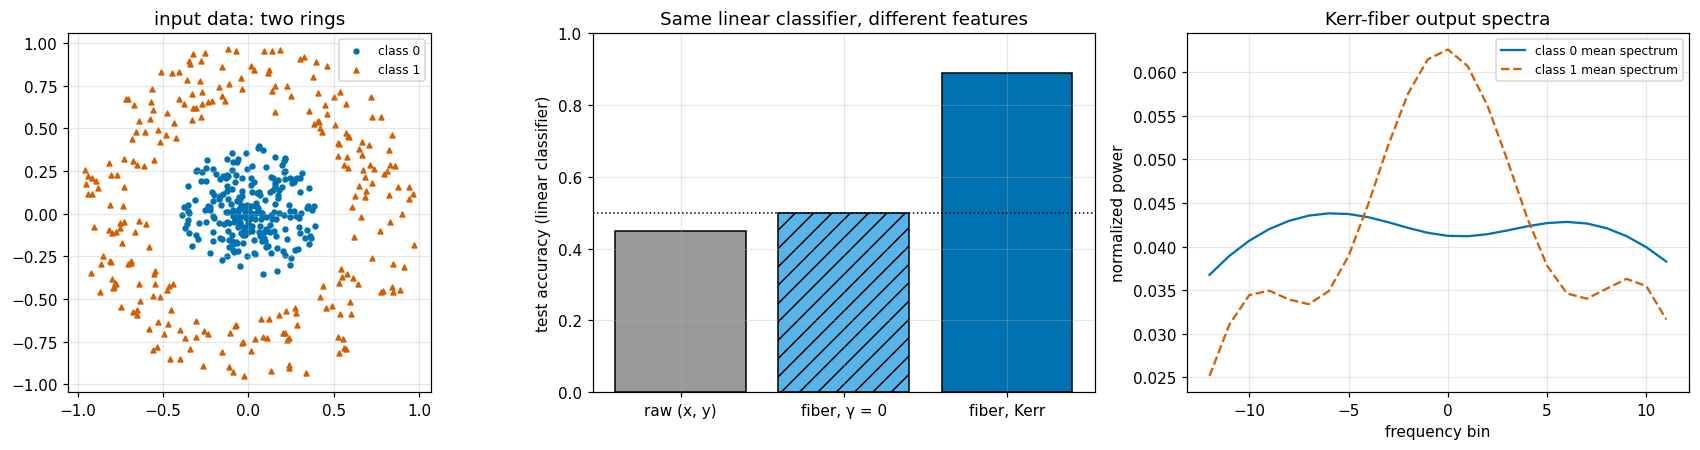

                model  test_accuracy
               raw_xy           0.45
fiber_dispersion_only           0.50
           fiber_kerr           0.89
Figure: left, an inner disk and an outer ring. Middle, the raw linear classifier and the dispersion-only fiber sit near the dotted chance line; the Kerr fiber reaches about 0.89. Right, the two classes have visibly different average output spectra after nonlinear propagation.


In [5]:
f = pd.read_csv(OUT / 'nlse_features.csv'); res = pd.read_csv(OUT / 'nlse_results.csv')
feat_cols = [c for c in f.columns if c.startswith('f')]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for lab, mk in ((0, 'o'), (1, '^')):
    s = f[f.label == lab]
    ax[0].scatter(s.x, s.y, s=10, marker=mk, label=f'class {lab}')
ax[0].set_aspect('equal'); ax[0].set_title('input data: two rings'); ax[0].legend(fontsize=8)
ax[1].bar(['raw (x, y)', 'fiber, γ = 0', 'fiber, Kerr'], res.test_accuracy, color=['#999999', '#56B4E9', '#0072B2'],
          hatch=['', '//', ''], edgecolor='k')
ax[1].axhline(0.5, color='k', ls=':', lw=1); ax[1].set_ylim(0, 1); ax[1].set_ylabel('test accuracy (linear classifier)')
ax[1].set_title('Same linear classifier, different features')
for lab, ls in ((0, '-'), (1, '--')):
    ax[2].plot(np.arange(24) - 12, f[f.label == lab][feat_cols].mean().values, ls, label=f'class {lab} mean spectrum')
ax[2].set_xlabel('frequency bin'); ax[2].set_ylabel('normalized power'); ax[2].set_title('Kerr-fiber output spectra'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(res.to_string(index=False))
print('Figure: left, an inner disk and an outer ring. Middle, the raw linear classifier and the dispersion-only fiber '
      'sit near the dotted chance line; the Kerr fiber reaches about 0.89. Right, the two classes have visibly different '
      'average output spectra after nonlinear propagation.')

**A bug worth remembering.** The first version scored 0.645 with $\gamma = 0$, where 0.5 is the only honest answer. The dispersion-only features are constant up to $10^{-17}$ rounding error; standardizing them blew that noise up to unit size, and even after shrinking it the classifier read the *sign* of the noise. The fix was to drop features that are constant to $10^{-9}$ relative. Lesson: a classifier will happily "learn" floating-point artifacts, so always run a control where the answer must be chance.

---
## 3. Physics-inspired algorithms: the Phase Stretch Transform

**In plain words.** Live cells are mostly water and nearly invisible without stains. PST, inspired by time stretch, treats the image like a wave through a dispersive medium and keeps the phase; edges pick up the most phase, so faint cell boundaries pop out (the paper's Figure 2) [19], [20].

$$\text{PST}[I] = \angle\,\mathcal F^{-1}\!\left\{\mathcal F\{\tilde I\}\, e^{-i\varphi(\rho)}\right\},\qquad \varphi(\rho) = S\,\frac{W\rho\arctan(W\rho) - \tfrac12\ln(1+(W\rho)^2)}{\max}$$
where $\tilde I$ is the low-pass-filtered image. Below the C output is compared, pixel by pixel, with an independent NumPy implementation of the same equations.

In [6]:
build_and_run('pst')

gcc -std=c89 -pedantic -Wall -Wextra pst.c -> exit 0; no warnings


PST on a 256x256 image with 40 faint cells (contrast 3%, noise 1%)
S = 0.50, W = 15.0, sigma_LPF = 0.15, edge threshold = 92% quantile
wrote cells_input.pgm, pst_feature.pgm, pst_edges.pgm (+ .bin float64 copies)



max |C PST - NumPy PST| = 9.0e-14


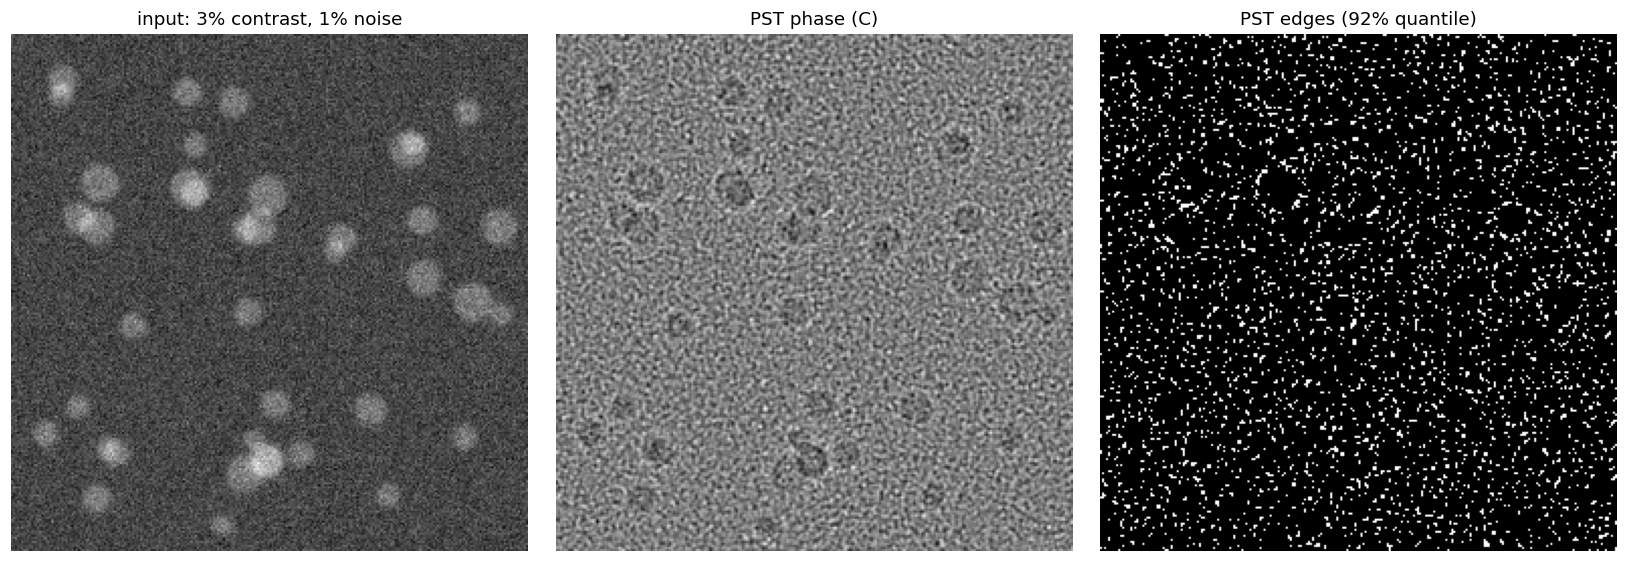

Figure: left, an almost uniform grey field where the cells are hard to see. Middle, the PST phase shows bright rings at every cell boundary. Right, thresholding the phase leaves closed outlines of the cells.


In [7]:
NX = NY = 256
img = np.fromfile(OUT / 'cells_input.bin', dtype=np.float64).reshape(NY, NX)
feat_c = np.fromfile(OUT / 'pst_feature.bin', dtype=np.float64).reshape(NY, NX)
edges = (np.frombuffer(open(OUT / 'pst_edges.pgm', 'rb').read()[-NX*NY:], dtype=np.uint8).reshape(NY, NX) > 0)

# independent NumPy PST with the same grid and parameters
S, W, sig = 0.5, 15.0, 0.15
U, V = np.meshgrid(np.fft.fftfreq(NX), np.fft.fftfreq(NY))
rho = np.hypot(U, V)
phi = W*rho*np.arctan(W*rho) - 0.5*np.log(1 + (W*rho)**2)
lpf = np.exp(-0.5*(rho/(sig/np.sqrt(np.log(2))))**2)
smooth = np.real(np.fft.ifft2(np.fft.fft2(img)*lpf))
feat_np = np.angle(np.fft.ifft2(np.fft.fft2(smooth)*np.exp(-1j*S*phi/phi.max())))
feat_np = (feat_np - feat_np.min())/(feat_np.max() - feat_np.min())
print(f'max |C PST - NumPy PST| = {np.abs(feat_c - feat_np).max():.1e}')

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a_, im, title in zip(ax, (img, feat_c, edges), ('input: 3% contrast, 1% noise', 'PST phase (C)', 'PST edges (92% quantile)')):
    a_.imshow(im, cmap='gray'); a_.set_title(title); a_.axis('off')
plt.tight_layout(); plt.show()
print('Figure: left, an almost uniform grey field where the cells are hard to see. Middle, the PST phase shows bright '
      'rings at every cell boundary. Right, thresholding the phase leaves closed outlines of the cells.')

---
## 4. Discovering physics: can a program find the law of a falling apple?

**In plain words.** Section 3 of the paper asks whether a machine watching an apple fall could write down $y = y_0 + v_0t - \tfrac12gt^2$. A small, interpretable version: fit noisy heights against a **library** of candidate terms $\{1, t, t^2, t^3, t^4, \sin t, \cos t\}$ and keep only the terms the data really need.

The program tries three methods and reports honestly what each finds:
1. **plain least squares**: fits the noise perfectly with nonsense coefficients, because on $0 \le t \le 2.4$ the library is nearly collinear;
2. **STLSQ thresholding** (as in SINDy): nothing gets removed, for the same reason;
3. **backward elimination** by an information criterion: **AIC** (penalty 2 per term) still keeps a spurious $\cos t \approx 1 - t^2/2$; **BIC** (penalty $\ln n$ per term) finds the true three-term law.

In [8]:
build_and_run('discover')

gcc -std=c89 -pedantic -Wall -Wextra discover.c -> exit 0; no warnings
full least squares (all 7 library terms):
  1: +14.448  t: +32.458  t^2: -11.418  t^3: -3.606  t^4: +0.892  sin(t): -20.456  cos(t): -12.937  
STLSQ with lambda = 0.15 after 1 round(s): 7 of 7 terms kept -> collinear library: every coefficient is large, nothing gets thresholded

measurement noise level: 0.05 m

backward elimination by AIC (penalty 2.00 per term):
  drop t^3     -> 6 terms, AIC = -350.31
  drop t^4     -> 5 terms, AIC = -351.99
  drop sin(t)  -> 4 terms, AIC = -353.43
  discovered law:  y(t) = +1.8037 1 +11.8602 t -4.9370 t^2 -0.2751 cos(t)
  residual RMS 0.0517 m
  -> kept a spurious term: on 0 <= t <= 2.4, cos(t) ~ 1 - t^2/2 mimics the polynomial

backward elimination by BIC (penalty 4.11 per term):
  drop t^3     -> 6 terms, BIC = -337.64
  drop t^4     -> 5 terms, BIC = -341.44
  drop sin(t)  -> 4 terms, BIC = -344.99
  drop cos(t)  -> 3 terms, BIC = -346.49
  discovered law:  y(t) = +1.5050 1 +1

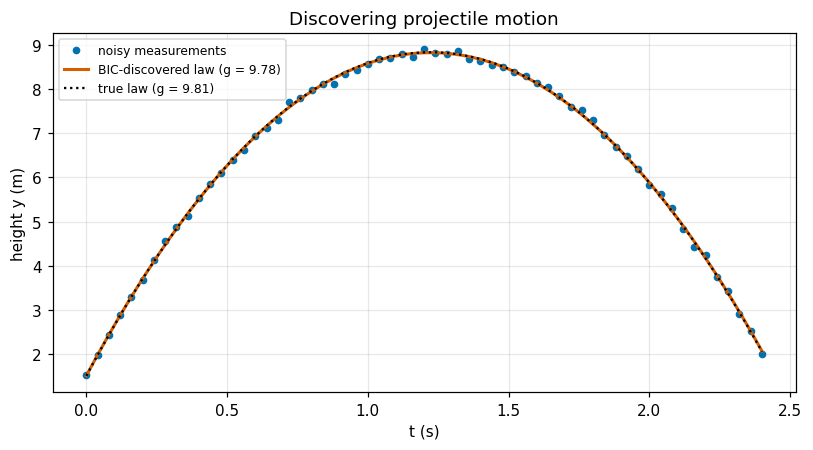

Figure: measurements trace an arch; the discovered parabola and the true law overlap almost exactly.


In [9]:
d = pd.read_csv(OUT / 'discover_data.csv')
tt = np.linspace(0, 2.4, 200)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(d.t, d.y_measured, 'o', ms=4, label='noisy measurements')
ax.plot(tt, 1.5050 + 11.9730*tt - 4.8922*tt**2, '-', lw=2, label='BIC-discovered law (g = 9.78)')
ax.plot(tt, 1.5 + 12*tt - 4.905*tt**2, ':', color='k', label='true law (g = 9.81)')
ax.set_xlabel('t (s)'); ax.set_ylabel('height y (m)'); ax.legend(fontsize=8); ax.set_title('Discovering projectile motion')
plt.tight_layout(); plt.show()
print('Figure: measurements trace an arch; the discovered parabola and the true law overlap almost exactly.')

---
## 4b. The same kernels on the GPU: CUDA (nvcc) vs gcc on the CPU, strict builds

Two programs do real number-crunching, so each gets a CUDA version that must reproduce its CPU result:

| CPU (ANSI C89, gcc) | GPU (CUDA C++, nvcc) | how it is parallel |
|---|---|---|
| `nlse_kernel.c`: one pulse at a time, own radix-2 FFT | `nlse_cuda.cu` | **one batched cuFFT** (`cufftPlanMany`, batch = every sample) plus element-wise kernels for dispersion and the Kerr phase |
| `pst.c`: own 2-D FFT (rows then columns) | `pst_cuda.cu` | **2-D cuFFT** plus element-wise low-pass, phase-kernel and angle kernels |

**Strict builds** (`c/build_strict.bat`): gcc with `-std=c89 -pedantic -Wall -Wextra -Werror`, nvcc with `-Werror all-warnings` and MSVC host warnings at `/W4 /WX`. Any warning stops the build.

`pst_cuda.exe pgm in.pgm out.pgm` also runs PST on **any 8-bit grayscale PGM frame**, e.g. a dim camera frame, for contrast and edge enhancement.

In [10]:
log = subprocess.run(['cmd', '/c', str(SRC / 'build_strict.bat')], capture_output=True, text=True, cwd=SRC)
print('\n'.join(l for l in (log.stdout + log.stderr).splitlines() if l.startswith(('===', '  built', 'Build')) or 'error' in l.lower()))

def run(*args):
    r = subprocess.run([str(OUT / args[0])] + list(args[1:]), capture_output=True, text=True, cwd=OUT)
    return (r.stdout + r.stderr).strip()

print(run('nlse_cuda.exe', 'check', 'nlse_features.csv', 'nlse_features_gpu.bin'))
print(run('pst_cuda.exe', 'bin', 'cells_input.bin', '256', '256', 'pst_feature_gpu.bin'))
print(run('pst_cuda.exe', 'pgm', 'cells_input.pgm', 'pst_frame_gpu.pgm'))

f = pd.read_csv(OUT / 'nlse_features.csv')
cpu_f = f[[c for c in f.columns if c.startswith('f')]].values
gpu_f = np.fromfile(OUT / 'nlse_features_gpu.bin').reshape(cpu_f.shape)
print(f'\nNLSE features, GPU vs CPU: max abs diff {np.abs(gpu_f - cpu_f).max():.1e} (features ~{np.median(cpu_f):.3f}), '
      f'correlation {np.corrcoef(gpu_f.ravel(), cpu_f.ravel())[0, 1]:.13f}')
pst_c, pst_g = np.fromfile(OUT / 'pst_feature.bin'), np.fromfile(OUT / 'pst_feature_gpu.bin')
print(f'PST, GPU vs CPU: max abs diff {np.abs(pst_c - pst_g).max():.1e}')

=== CPU: gcc -std=c89 -pedantic -Wall -Wextra -Werror ===
  built kalman.exe
  built nlse_kernel.exe
  built pst.exe
  built discover.exe
=== GPU: nvcc -Werror all-warnings ===
  built nlse_cuda.exe
  built pst_cuda.exe
Build OK.
GPU features for 500 samples in 15.20 ms -> nlse_features_gpu.bin


GPU PST 256x256 in 0.518 ms -> pst_feature_gpu.bin
GPU PST 256x256 frame in 0.517 ms -> pst_frame_gpu.pgm

NLSE features, GPU vs CPU: max abs diff 8.6e-08 (features ~0.040), correlation 0.9999999999996
PST, GPU vs CPU: max abs diff 1.2e-13


**Why the NLSE agreement is $10^{-7}$ and not $10^{-15}$.** cuFFT and the hand-written radix-2 FFT round differently at the level of $10^{-16}$. PST is linear, so that rounding stays at $10^{-13}$. The NLSE is **nonlinear**: 80 Kerr steps feed each step's rounding back into the next, and the differences grow to about $10^{-7}$ absolute. That's physics (sensitivity of nonlinear propagation), not a bug; a bug would show up as percent-level differences.

In [11]:
print(run('nlse_kernel.exe', 'bench', '2000'))
print(run('nlse_cuda.exe', 'bench', '2000'))
print(run('nlse_cuda.exe', 'bench', '100000'))

CPU (ANSI C, one core): 2000 samples x 80 split steps in 2581.0 ms  (1290.5 us/sample)
GPU (NVIDIA GeForce RTX 4060): 2000 samples x 80 split steps in 52.87 ms  (26.44 us/sample)


GPU (NVIDIA GeForce RTX 4060): 100000 samples x 80 split steps in 2318.68 ms  (23.19 us/sample)


The batched GPU version is roughly **50× faster per sample** than one CPU core for this small (128-point) problem, and it keeps that rate at 100,000 samples, where the whole batch is a single cuFFT call per step. On the GPU the cost is dominated by launching ~6 kernels per split step, so larger grids or fused kernels would widen the gap further.

---
## 5. Conclusions: several ways to end this paper

The paper ends by saying the symbiosis of physics and AI "will surely transform" physics and optics. Here are alternative conclusions, each grounded in the experiments above and each written for a different reader. Pick one, or combine them.

### 5.1 The engineer's conclusion: latency and energy
Deep networks buy accuracy with billions of parameters, and the end of Moore's law makes that trade more expensive every year. The fiber experiment shows the alternative: a passive Kerr nonlinearity did the feature mapping that let a 24-weight linear classifier reach 0.89 accuracy on data a linear model could not separate (0.45). When physics supplies the nonlinear transform, the digital part shrinks to something a microcontroller, or an ANSI C loop, can run in real time.

### 5.2 The physicist's conclusion: discovery needs priors
"Discovering physics" from data is not magic. With a candidate library, plain regression fit the noise perfectly and returned $g = 22.8\ \text{m/s}^2$; AIC kept a spurious $\cos t$; only a stronger simplicity prior (BIC) returned $g = 9.78$. A machine discovers laws only as well as its library, its sampling range, and its preference for simplicity allow, which is exactly the physical knowledge the paper says must be blended in.

### 5.3 The skeptic's conclusion: controls before claims
Every symbiosis claim needs a control where the right answer is known. Our dispersion-only fiber *had* to score 0.5; it scored 0.645 until we found the classifier was reading floating-point noise. Physics gives us such controls for free (conservation laws, symmetries, the fact that a pure phase filter cannot change $|\tilde E|$). Interpretability, the paper's main complaint about black boxes, starts with building these checks into the pipeline.

### 5.4 The computer engineer's conclusion: small, portable, verifiable code
Physics-based models are compact enough to write in a few hundred lines of portable C: a Kalman filter, a split-step NLSE solver, a 2-D FFT edge detector, a sparse regressor, all with no dependencies and zero compiler warnings. That is the deployability argument for physics-AI symbiosis: models whose every line is an equation can run on edge hardware, be audited, and be checked against an independent implementation (C vs NumPy PST agree to rounding error). The same equations also map directly onto a GPU: a batched cuFFT version of the fiber kernel ran about 50 times faster per sample than one CPU core while reproducing its output.

### 5.5 Beyond spectral regression: what scientific machine learning should do next
Much of photonic machine learning so far is spectral regression: map a measured spectrum to a label or a number. The paper points further. The next steps are **dynamics** (learn $\dot{\mathbf x} = f(\mathbf x)$, not just $y(t)$), **operators** (learn the map between whole fields, as in the NLSE), **uncertainty** (the Kalman covariance $P$ is a built-in error bar; learned models need one too), and **closing the loop** (use the learned model to choose the next measurement, as in coded-illumination microscopy). Regression is where scientific ML starts, not where it should stop.

### 5.6 The educator's conclusion: four programs, one idea
The same idea runs through every section: put the known physics in the structure and let data fill in only what is unknown. A student can see it in an afternoon: the Kalman gain weighs model against sensor, the fiber does the kernel, PST uses diffraction as a filter, and the information criterion encodes Occam's razor. Teaching AI alongside the physics it imitates makes both easier to understand.

### 5.7 The one-paragraph abstract version
Physics and AI are complementary: physics is compact, interpretable and extrapolates; data-driven models are flexible but costly and opaque. Four minimal ANSI C experiments, a Kalman filter, a nonlinear-optics kernel, the Phase Stretch Transform and sparse law discovery, show the blend outperforming either part alone, and also show its failure modes: collinear libraries, weak priors, and models that learn numerical noise. The future of the field is less about bigger networks and more about better-placed physics.

### 5.8 The short version
Physics is the prior, data is the correction, and the control experiment keeps both honest.

---
## 6. Assignments built from the paper

Each has a deliverable and a check you can verify yourself. Levels: **[A]** first course, **[B]** intermediate, **[C]** advanced or project-scale.

**Kalman filter (Introduction)**
1. **[A]** Change the sensor noise `sig_meas` to 0.5, 2 and 8 m. Plot Kalman RMSE vs sensor RMSE. *Check:* the Kalman RMSE is always below the sensor RMSE.
2. **[B]** Set the process noise $Q$ ten times too small, then ten times too large. Explain in two sentences what goes wrong in each case (over-trusting the model vs over-trusting the sensor).
3. **[C]** Add a constant-acceleration state (3-state filter) and drop a ball. *Check:* the filter's estimate of $g$ converges to 9.81.

**Nature as a computer (Section 2)**
4. **[A]** Run `nlse_kernel` with $\gamma$ = 0, 1, 3, 6, 10. Plot accuracy vs $\gamma$. *Check:* $\gamma = 0$ gives 0.5.
5. **[B]** Prove, in one line, that a pure dispersion filter $e^{-i\beta_2L\omega^2/2}$ cannot change $|\tilde A(\omega)|^2$. Then explain why intensity in *time* would still change.
6. **[B]** Replace the fiber with a numerical RBF kernel ($e^{-\|\mathbf u - \mathbf v\|^2/2\sigma^2}$) and compare accuracy and operation count against the optical kernel.
7. **[C]** Add detector noise and 8-bit quantization to the output spectrum. How much accuracy is lost? (The paper claims robustness to both.)

**Phase Stretch Transform (Section 2)**
8. **[A]** Vary $S$ and $W$ in `pst.c`; make a 3×3 grid of outputs. Describe which edges appear or disappear.
9. **[B]** Lower the cell contrast from 3% to 1% and raise the noise to 2%. Find the parameters where PST still outlines the cells.
10. **[C]** Count the cells automatically (connected components on the edge map) and report precision and recall against the known cell positions.

**Discovering physics (Section 3)**
11. **[A]** Extend the time range from 2.4 s to 5 s. Does AIC still keep $\cos t$? Explain using a Taylor series.
12. **[B]** Compute the condition number of the library matrix $\Theta^\top\Theta$ for both time ranges. Relate it to the failure of plain least squares.
13. **[C]** Discover the *differential* law instead: estimate $\dot v$ from the data by finite differences and show the library regression returns $\dot v = -g$ with no other terms (true SINDy).

**Writing and reading**
14. **[A]** Summarize each of the paper's three themes in three sentences, with one example from its references.
15. **[B]** Pick one reference ([12], [16], [19], [25] or [29]) and write a one-page critical review: what is the physics, what is learned, what would break it?
16. **[B]** Write your own conclusion (150 words) in the style of section 5, using a number you measured yourself.

## References

[1] B. Jalali, A. Kadambi, and V. Roychowdhury, "Physics-AI symbiosis," arXiv:2109.05959, 2021.

[2] R. E. Kalman, "A new approach to linear filtering and prediction problems," *J. Basic Eng.*, vol. 82, no. 1, pp. 35–45, 1960.

[3] T. Zhou, F. Scalzo, and B. Jalali, "Nonlinear Schrödinger kernel computing for single-shot data acquisition and inference," arXiv:2012.08615, 2020.

[4] M. H. Asghari and B. Jalali, "Edge detection in digital images using dispersive phase stretch transform," *Int. J. Biomed. Imaging*, 2015.

[5] S. L. Brunton, J. L. Proctor, and J. N. Kutz, "Discovering governing equations from data by sparse identification of nonlinear dynamical systems," *Proc. Natl. Acad. Sci.*, vol. 113, no. 15, pp. 3932–3937, 2016.

[6] M. Schmidt and H. Lipson, "Distilling free-form natural laws from experimental data," *Science*, vol. 324, no. 5923, pp. 81–85, 2009.

[7] G. P. Agrawal, *Nonlinear Fiber Optics*, 6th ed. London, U.K.: Academic Press, 2019.

*[1]–[2], [4], [6] are cited in the paper itself; the others are from memory: verify before citing.*